In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## LOADING THE DATA

In [10]:
movies = pd.read_csv('data/TMDB_230000_movies.csv')
movies.head()

,title,genres,overview,cast,director,producers,writers,poster_path,year_norm
0,Ariel,"Comedy, Drama, Romance, Crime",A Finnish man goes to the city to find a job a...,"Tarja Keinänen, Marja Packalén, Kari Helaseppä...",Aki Kaurismäki,Aki Kaurismäki,Aki Kaurismäki,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,0.681481
1,Shadows in Paradise,"Comedy, Drama, Romance","Nikander, a rubbish collector and would-be ent...","Ari Korhonen, Mari Rantasila, Erkki Rissanen, ...",Aki Kaurismäki,Mika Kaurismäki,Aki Kaurismäki,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,0.666667
2,Four Rooms,Comedy,It's Ted the Bellhop's first night on the job....,"Marisa Tomei, Kimberly Blair, Madonna, Tamlyn ...","Quentin Tarantino, Robert Rodriguez, Alexandre...","Lawrence Bender, Quentin Tarantino, Alexandre ...","Quentin Tarantino, Robert Rodriguez, Alexandre...",/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,0.733333
3,Judgment Night,"Action, Crime, Thriller","Four young friends, while taking a shortcut en...","Doug Wert, Angela Alvarado, Everlast, Sean O'G...",Stephen Hopkins,"Marilyn Vance, Gene Levy, Lloyd Segan","Lewis Colick, Jere Cunningham",/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,0.718519
4,Star Wars,"Adventure, Action, Science Fiction",Princess Leia is captured and held hostage by ...,"Jeremy Sinden, Michael Leader, Derek Lyons, Al...",George Lucas,"Gary Kurtz, George Lucas",George Lucas,/6FfCtAuVAW8XJjZ7eWeLibRLWTw.jpg,0.600000


## EXPLORING DATA

In [9]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 237898 entries, 0 to 237897
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   title        237898 non-null  object 
 1   genres       237898 non-null  object 
 2   overview     237898 non-null  object 
 3   cast         237898 non-null  object 
 4   director     237898 non-null  object 
 5   producers    237898 non-null  object 
 6   writers      237898 non-null  object 
 7   poster_path  237898 non-null  object 
 8   year_norm    237898 non-null  float64
dtypes: float64(1), object(8)
memory usage: 16.3+ MB


In [10]:
movies.isnull().sum()

title          0
genres         0
overview       0
cast           0
director       0
producers      0
writers        0
poster_path    0
year_norm      0
dtype: int64

## CONTENT-BASED RECOMMENDATION

This one looks at the features of the movies themselves — genre, director, cast, keywords. If you liked Inception, it finds other movies with similar characteristics. Similarity will be computed using Cosine Similarity on a TF-IDF matrix built from the metadata.

In [11]:
movies['features'] = movies['genres'] + ' ' + movies['overview'] + ' ' + movies['cast'] + ' ' + movies['director'] + ' ' + movies['producers'] + ' ' + movies['writers'] 

🎯 TF‑IDF = “How important is this word for describing this movie?”
TF‑IDF stands for:

TF — Term Frequency  
How often a word appears in a document (movie description).

IDF — Inverse Document Frequency  
How rare that word is across the entire dataset.

Then it multiplies them:

TF-IDF
=
TF
×
IDF
🧠 Why this matters for your recommender
TF‑IDF gives high weight to words that are:

frequent in this movie

rare in other movies

And low weight to words that are:

common everywhere (“the”, “movie”, “story”, “man”, “life”)

movies x corpus
cell values= TFXIDF score of a word in this movie

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=50000  # optional, keeps it manageable
)

tfidf_matrix = tfidf.fit_transform(movies['features'])

tfidf_matrix


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 12411453 stored elements and shape (237898, 50000)>

In [13]:
from sklearn.metrics.pairwise import linear_kernel

# Precomputing the full matrix leads to a memory crash (237k x 237k)
# Thats why we compute similarity on-the-fly per movie
indices = pd.Series(movies.index, index=movies['title']).drop_duplicates()

In [14]:
def get_recommendations(title, top_n=10):
    idx = indices[title]
    sim_scores = linear_kernel(tfidf_matrix[idx], tfidf_matrix).flatten()
    sim_scores[idx] = 0
    top_indices = sim_scores.argsort()[::-1][:top_n]
    return movies['title'].iloc[top_indices]

In [15]:
get_recommendations("Inception")

92953                                Dunkirk
54296                           Interstellar
213044                             Promcakes
24063                  The Dark Knight Rises
154904                            Tarantella
21340                              Doodlebug
5936                               Following
106915                               Larceny
824                             The Prestige
86035     Dreams: Cinema of the Subconscious
Name: title, dtype: object

## COLLABORATIVE FILTERING

In [1]:
import pandas as pd
from surprise import SVD, Dataset, Reader
from surprise.model_selection import cross_validate
from collections import defaultdict

ratings = pd.read_csv('data/ratings.csv')       # userId, movieId, rating, timestamp
ml_movies = pd.read_csv('data/movies.csv')       # movieId, title, genres

print(f"Ratings: {len(ratings):,} rows")
print(f"Users: {ratings['userId'].nunique():,}")
print(f"Movies: {ratings['movieId'].nunique():,}")
ratings.head()

Ratings: 100,836 rows
Users: 610
Movies: 9,724


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


### Training the SVD Model

SVD (Singular Value Decomposition) decomposes the user-movie rating matrix into latent factors.  
It learns hidden patterns like *"this user likes action movies with complex plots"* without being told explicitly.

In [2]:
reader = Reader(rating_scale=(0.5, 5.0))
data = Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)

svd_model = SVD(n_factors=50, n_epochs=20, random_state=42)
cv_results = cross_validate(svd_model, data, measures=['RMSE', 'MAE'], cv=5, verbose=True)

Evaluating RMSE, MAE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.8659  0.8653  0.8699  0.8753  0.8713  0.8696  0.0037  
MAE (testset)     0.6675  0.6656  0.6688  0.6702  0.6677  0.6679  0.0015  
Fit time          0.49    0.48    0.50    0.46    0.47    0.48    0.02    
Test time         0.06    0.08    0.08    0.07    0.08    0.07    0.01    


In [3]:
import numpy as np

print(f"Mean RMSE: {np.mean(cv_results['test_rmse']):.4f}")
print(f"Mean MAE:  {np.mean(cv_results['test_mae']):.4f}")

Mean RMSE: 0.8696
Mean MAE:  0.6679


In [4]:
trainset = data.build_full_trainset()
svd_model.fit(trainset)
print("Model trained on full dataset.")

Model trained on full dataset.


In [5]:
def get_cf_recommendations(user_id, n=10):
    """
    Returns top-N movie recommendations for a given user_id.
    Excludes movies the user has already rated.
    """
    # Movies this user has already seen
    watched = set(ratings[ratings['userId'] == user_id]['movieId'])
    
    # All movies in the dataset
    all_movie_ids = ratings['movieId'].unique()
    
    # Predict rating for every unseen movie
    predictions = []
    for movie_id in all_movie_ids:
        if movie_id not in watched:
            pred = svd_model.predict(user_id, movie_id)
            predictions.append((movie_id, pred.est))
    
    # Sort by predicted rating
    predictions.sort(key=lambda x: x[1], reverse=True)
    top_ids = [p[0] for p in predictions[:n]]
    
    # Merge with movie titles
    result = ml_movies[ml_movies['movieId'].isin(top_ids)][['movieId', 'title', 'genres']].copy()
    result['predicted_rating'] = result['movieId'].map(dict(predictions[:n]))
    result = result.sort_values('predicted_rating', ascending=False).reset_index(drop=True)
    return result

### Collaborative filtering tryout

In [7]:
import matplotlib.pyplot as plt

# Pick a user and see what they rated highly
user_id = 1
user_ratings = ratings[ratings['userId'] == user_id].merge(ml_movies, on='movieId')
top_rated = user_ratings.sort_values('rating', ascending=False).head(5)[['title', 'genres', 'rating']]

print(f"User {user_id}'s top-rated movies:")
print(top_rated.to_string(index=False))
print()

print(f"CF Recommendations for User {user_id}:")
print(get_cf_recommendations(user_id, n=5)[['title', 'genres', 'predicted_rating']].to_string(index=False))

User 1's top-rated movies:
                                    title                    genres  rating
             M*A*S*H (a.k.a. MASH) (1970)          Comedy|Drama|War     5.0
                         Excalibur (1981)         Adventure|Fantasy     5.0
Indiana Jones and the Last Crusade (1989)          Action|Adventure     5.0
              Pink Floyd: The Wall (1982)             Drama|Musical     5.0
             From Russia with Love (1963) Action|Adventure|Thriller     5.0

CF Recommendations for User 1:
                           title                  genres  predicted_rating
Shawshank Redemption, The (1994)             Crime|Drama               5.0
      Singin' in the Rain (1952)  Comedy|Musical|Romance               5.0
              Rear Window (1954)        Mystery|Thriller               5.0
            Departed, The (2006)    Crime|Drama|Thriller               5.0
         Dark Knight, The (2008) Action|Crime|Drama|IMAX               5.0


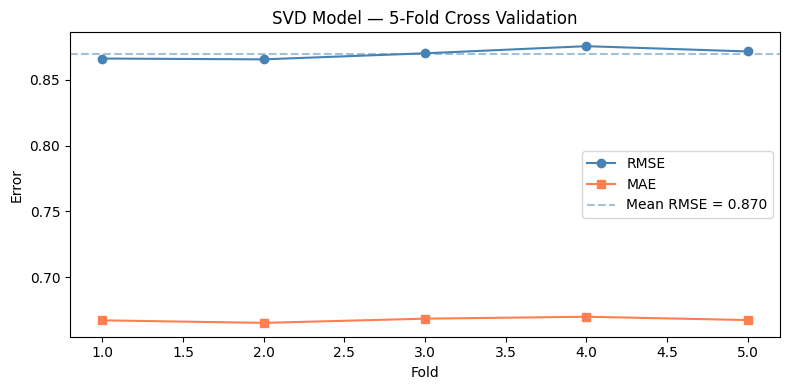

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, 6), cv_results['test_rmse'], marker='o', label='RMSE', color='steelblue')
plt.plot(range(1, 6), cv_results['test_mae'],  marker='s', label='MAE',  color='coral')
plt.axhline(np.mean(cv_results['test_rmse']), linestyle='--', color='steelblue', alpha=0.5, label=f"Mean RMSE = {np.mean(cv_results['test_rmse']):.3f}")
plt.xlabel('Fold')
plt.ylabel('Error')
plt.title('SVD Model — 5-Fold Cross Validation')
plt.legend()
plt.tight_layout()
plt.show()

## CHECK OVERLAP

Lets check how well the TMDB and MovieLens datasets overlap so we can decide whether a hybrid recommender is feasible.

In [11]:
print(f"  TMDB:      {len(movies):,} movies")
print(f"  MovieLens: {len(ml_movies):,} movies, {len(ratings):,} ratings")
print()

# ── 1. Column overview ─────────────────────────────────────────────────────────
print("=== TMDB columns ===")
print(movies.columns.tolist())
print()
print("=== MovieLens columns ===")
print(ml_movies.columns.tolist())
print()

# ── 2. Check for a shared ID (imdb_id / tmdbId) ───────────────────────────────
print("=== Shared ID check ===")
tmdb_cols = set(movies.columns.str.lower())
ml_cols   = set(ml_movies.columns.str.lower())

  TMDB:      237,898 movies
  MovieLens: 9,742 movies, 100,836 ratings

=== TMDB columns ===
['title', 'genres', 'overview', 'cast', 'director', 'producers', 'writers', 'poster_path', 'year_norm']

=== MovieLens columns ===
['movieId', 'title', 'genres']

=== Shared ID check ===


In [13]:
import re
# ── 3. Title-based overlap ─────────────────────────────────────────────────────
def normalise(title: str) -> str:
    """Lowercase, strip year suffixes like '(1995)', remove punctuation."""
    title = str(title).lower().strip()
    title = re.sub(r"\(\d{4}\)", "", title)       # remove (year)
    title = re.sub(r"[^a-z0-9\s]", "", title)    # remove punctuation
    title = re.sub(r"\s+", " ", title).strip()
    # move leading 'the', 'a', 'an' to end  e.g. "the matrix" → "matrix the"
    for article in ("the ", "a ", "an "):
        if title.startswith(article):
            title = title[len(article):] + " " + article.strip()
            break
    return title

print("=== Title-based overlap ===")
tmdb_titles = set(movies["title"].dropna().map(normalise))
ml_titles   = set(ml_movies["title"].dropna().map(normalise))

exact_overlap   = tmdb_titles & ml_titles
only_in_tmdb    = tmdb_titles - ml_titles
only_in_ml      = ml_titles   - tmdb_titles

print(f"  TMDB unique normalised titles:      {len(tmdb_titles):,}")
print(f"  MovieLens unique normalised titles: {len(ml_titles):,}")
print(f"  Exact matches:                      {len(exact_overlap):,}")
print(f"  Overlap rate (vs MovieLens):        {len(exact_overlap)/len(ml_titles)*100:.1f}%")
print(f"  Overlap rate (vs TMDB):             {len(exact_overlap)/len(tmdb_titles)*100:.1f}%")
print()

=== Title-based overlap ===
  TMDB unique normalised titles:      203,330
  MovieLens unique normalised titles: 9,441
  Exact matches:                      7,670
  Overlap rate (vs MovieLens):        81.2%
  Overlap rate (vs TMDB):             3.8%



In [35]:
# Correct year min and max from TMDB Dataset
YEAR_MIN = 1896
YEAR_MAX = 2031

In [30]:
# ── Helper functions ───────────────────────────────────────────────────────────
def normalise_title(title: str) -> str:
    """Lowercase, strip year suffix like '(1995)', remove punctuation."""
    title = str(title).lower().strip()
    title = re.sub(r"\(\d{4}\)", "", title)
    title = re.sub(r"[^a-z0-9\s]", "", title)
    title = re.sub(r"\s+", " ", title).strip()
    for article in ("the ", "a ", "an "):
        if title.startswith(article):
            title = title[len(article):] + " " + article.strip()
            break
    return title

def extract_ml_year(title: str):
    """Extract year from MovieLens format 'Toy Story (1995)' -> 1995."""
    match = re.search(r"\((\d{4})\)\s*$", str(title).strip())
    return int(match.group(1)) if match else None

def denorm_year(year_norm):
    """Convert TMDB normalised year back to calendar year."""
    try:
        return int(round(YEAR_MIN + float(year_norm) * (YEAR_MAX - YEAR_MIN)))
    except (TypeError, ValueError):
        return None

# ── Build join keys ────────────────────────────────────────────────────────────
ml_movies["title_norm"] = ml_movies["title"].map(normalise_title)
ml_movies["year"]       = ml_movies["title"].map(extract_ml_year).astype("Int64")
ml_movies["key"]        = ml_movies["title_norm"] + "|" + ml_movies["year"].astype(str)

movies["title_norm"] = movies["title"].map(normalise_title)
movies["year"]       = movies["year_norm"].map(denorm_year).astype("Int64")
movies["key"]        = movies["title_norm"] + "|" + movies["year"].astype(str)

# ── Title-only overlap (baseline) ─────────────────────────────────────────────
print("=== Title-only overlap (baseline) ===")
title_overlap = set(movies["title_norm"]) & set(ml_movies["title_norm"])
print(f"  Title matches: {len(title_overlap):,} / {len(ml_movies):,} ML movies "
      f"({len(title_overlap)/len(ml_movies)*100:.1f}%)")

# ── Title + year overlap (safe) ────────────────────────────────────────────────
print()
print("=== Title + year overlap (safe join) ===")
tmdb_keys   = set(movies["key"])
ml_keys     = set(ml_movies["key"])
key_overlap = tmdb_keys & ml_keys
only_in_ml  = ml_keys - tmdb_keys

print(f"  Title+year matches:  {len(key_overlap):,} / {len(ml_movies):,} ML movies "
      f"({len(key_overlap)/len(ml_movies)*100:.1f}%)")
print(f"  Lost vs title-only:  {len(title_overlap) - len(key_overlap):,} "
      f"(likely remake/year-shift collisions)")

# ── Inspect what the year filter removed ──────────────────────────────────────
print()
print("=== Titles removed by year filter (potential remakes) ===")
title_match_keys = set(ml_movies[ml_movies["title_norm"].isin(title_overlap)]["key"])
collisions       = title_match_keys - key_overlap
collision_df = (
    ml_movies[ml_movies["key"].isin(collisions)][["title", "year"]]
    .drop_duplicates()
    .head(15)
)
for _, row in collision_df.iterrows():
    print(f"  ⚠  {row['title']}  (ML year: {row['year']})")

# ── Sample unmatched ───────────────────────────────────────────────────────────
print()
print("=== Sample MovieLens movies with no TMDB match ===")
unmatched = ml_movies[ml_movies["key"].isin(only_in_ml)][["title", "year"]].head(10)
for _, row in unmatched.iterrows():
    print(f"  ✗  {row['title']}")

# ── Ratings coverage ──────────────────────────────────────────────────────────
print()
print("=== Ratings coverage for title+year matched movies ===")
matched_ids     = ml_movies[ml_movies["key"].isin(key_overlap)]["movieId"]
ratings_covered = ratings[ratings["movieId"].isin(matched_ids)]
print(f"  {len(ratings_covered):,} / {len(ratings):,} ratings "
      f"({len(ratings_covered)/len(ratings)*100:.1f}%) are on matched movies")

# ── Edge case: ML titles with no year ─────────────────────────────────────────
print()
missing_year = ml_movies["year"].isna().sum()
print(f"=== MovieLens titles with no year in string: {missing_year} ===")
if missing_year:
    print(ml_movies[ml_movies["year"].isna()]["title"].head(10).tolist())

=== Title-only overlap (baseline) ===
  Title matches: 7,670 / 9,742 ML movies (78.7%)

=== Title + year overlap (safe join) ===
  Title+year matches:  7,452 / 9,742 ML movies (76.5%)
  Lost vs title-only:  218 (likely remake/year-shift collisions)

=== Titles removed by year filter (potential remakes) ===
  ⚠  Othello (1995)  (ML year: 1995)
  ⚠  Boys of St. Vincent, The (1992)  (ML year: 1992)
  ⚠  Crumb (1994)  (ML year: 1994)
  ⚠  Love & Human Remains (1993)  (ML year: 1993)
  ⚠  Mute Witness (1994)  (ML year: 1994)
  ⚠  Nadja (1994)  (ML year: 1994)
  ⚠  Castle Freak (1995)  (ML year: 1995)
  ⚠  Don Juan DeMarco (1995)  (ML year: 1995)
  ⚠  Houseguest (1994)  (ML year: 1994)
  ⚠  Beyond Bedlam (1993)  (ML year: 1993)
  ⚠  Nina Takes a Lover (1994)  (ML year: 1994)
  ⚠  Priest (1994)  (ML year: 1994)
  ⚠  Swimming with Sharks (1995)  (ML year: 1995)
  ⚠  Underneath (1995)  (ML year: 1995)
  ⚠  Walking Dead, The (1995)  (ML year: 1995)

=== Sample MovieLens movies with no TMDB match

In [28]:
ml_movies[ml_movies["title"]=="Sabrina (1995)"]

,movieId,title,genres,title_norm,year,key
6,7,Sabrina (1995),Comedy|Romance,sabrina,1995.0,sabrina|1995.0


In [29]:
movies[movies["title"]=="Sabrina"]

,title,genres,overview,cast,director,producers,writers,poster_path,year_norm,title_norm,year,key
3139,Sabrina,"Comedy, Romance, Drama","After her return from school in Paris, a playb...","Walter Hampden, Kay E. Kuter, Chuck Hamilton, ...",Billy Wilder,Billy Wilder,"Billy Wilder, Ernest Lehman, Samuel A. Taylor",/e1Po9NDrH7IJZhv89467gJH5FS0.jpg,0.429630,sabrina,1954,sabrina|1954
6073,Sabrina,"Romance, Drama, Comedy","After her return from school in Paris, a playb...","Nancy Marchand, Philippa Cooper, Anthony Monda...",Sydney Pollack,"Lindsay Doran, Ronald L. Schwary, Sydney Polla...","Marilyn Bergman, Billy Wilder, Samuel A. Taylo...",/i8PbLJDPU7vCwwscWD625oHbJy.jpg,0.733333,sabrina,1995,sabrina|1995
114838,Sabrina,"Horror, Thriller",A toy manufacturer and his wife are terrorized...,"Christian Sugiono, Richelle Georgette Skornick...",Rocky Soraya,"Rocky Soraya, Raam Soraya","Riheam Junianti, Rocky Soraya, Fajar Umbara",/zheAqvuUgk9L2ElLHgYo92WJIdO.jpg,0.903704,sabrina,2018,sabrina|2018


In [32]:
tmdb = movies.copy()

In [34]:
#New pipeline trying to catch also movies for which years have +-1 difference and the same title
# ── Helper functions ───────────────────────────────────────────────────────────
def strip_alternate_titles(title: str) -> str:
    """
    Remove alternate/foreign titles from ML title strings. Examples:
      'Twelve Monkeys (a.k.a. 12 Monkeys) (1995)'  -> 'Twelve Monkeys (1995)'
      'City of Lost Children, The (Cite des enfants...) (1995)' -> 'City of Lost Children, The (1995)'
      'Seven (a.k.a. Se7en) (1995)'  -> 'Seven (1995)'

    Strategy: if there are multiple (...) groups and the last one is a year,
    keep only the last (year) group and the text before the first (.
    """
    title = str(title).strip()
    # Match: everything before the first '(' that isn't the year, then the year at the end
    match = re.match(r"^(.*?)\s*\((?!\d{4}\))[^)]*\)\s*(\(\d{4}\))\s*$", title)
    if match:
        return f"{match.group(1).strip()} {match.group(2)}"
    return title


def normalise_title(title: str) -> str:
    """Lowercase, strip year suffix, remove punctuation, move leading articles."""
    title = strip_alternate_titles(title)
    title = title.lower().strip()
    title = re.sub(r"\(\d{4}\)", "", title)       # remove (year)
    title = re.sub(r"[^a-z0-9\s]", "", title)    # remove punctuation
    title = re.sub(r"\s+", " ", title).strip()
    for article in ("the ", "a ", "an "):
        if title.startswith(article):
            title = title[len(article):] + " " + article.strip()
            break
    return title


def extract_ml_year(title: str):
    """Extract year from ML format 'Toy Story (1995)' -> 1995."""
    title = strip_alternate_titles(str(title).strip())
    match = re.search(r"\((\d{4})\)\s*$", title)
    return int(match.group(1)) if match else None


def denorm_year(year_norm):
    """Convert TMDB normalised year back to calendar year."""
    try:
        return int(round(YEAR_MIN + float(year_norm) * (YEAR_MAX - YEAR_MIN)))
    except (TypeError, ValueError):
        return None


# ── Build normalised columns ───────────────────────────────────────────────────
ml_movies["title_norm"] = ml_movies["title"].map(normalise_title)
ml_movies["year"]       = ml_movies["title"].map(extract_ml_year).astype("Int64")

tmdb["title_norm"] = tmdb["title"].map(normalise_title)
tmdb["year"]       = tmdb["year_norm"].map(denorm_year).astype("Int64")

# Build a lookup: title_norm -> set of years available in TMDB
tmdb_year_lookup = tmdb.groupby("title_norm")["year"].apply(set).to_dict()


# ── Match functions ────────────────────────────────────────────────────────────
def exact_key(row) -> str:
    return f"{row['title_norm']}|{row['year']}"


def fuzzy_match(row) -> bool:
    """True if TMDB has this title with a year within ±1 of ML year."""
    title = row["title_norm"]
    year  = row["year"]
    if pd.isna(year) or title not in tmdb_year_lookup:
        return False
    tmdb_years = tmdb_year_lookup[title]
    return any(abs(year - ty) <= 1 for ty in tmdb_years if pd.notna(ty))


# ── Overlap passes ─────────────────────────────────────────────────────────────
print("=== Title-only overlap (baseline) ===")
title_overlap = set(tmdb["title_norm"]) & set(ml_movies["title_norm"])
print(f"  Title matches: {len(title_overlap):,} / {len(ml_movies):,} ML movies "
      f"({len(title_overlap)/len(ml_movies)*100:.1f}%)")

print()
print("=== Title + exact year ===")
tmdb_keys   = set(tmdb["title_norm"] + "|" + tmdb["year"].astype(str))
ml_movies["exact_key"] = ml_movies.apply(exact_key, axis=1)
exact_match_mask = ml_movies["exact_key"].isin(tmdb_keys)
n_exact = exact_match_mask.sum()
print(f"  Exact matches: {n_exact:,} / {len(ml_movies):,} ML movies "
      f"({n_exact/len(ml_movies)*100:.1f}%)")

print()
print("=== Title + year ±1 (final safe join) ===")
fuzzy_match_mask  = ml_movies.apply(fuzzy_match, axis=1)
n_fuzzy_recovered = (fuzzy_match_mask & ~exact_match_mask).sum()
n_total_matched   = (exact_match_mask | fuzzy_match_mask).sum()
print(f"  Total matched: {n_total_matched:,} / {len(ml_movies):,} ML movies "
      f"({n_total_matched/len(ml_movies)*100:.1f}%)")
print(f"  Recovered by ±1 tolerance: {n_fuzzy_recovered:,} extra movies")

print()
print("=== Still unmatched after all fixes ===")
unmatched_mask = ~(exact_match_mask | fuzzy_match_mask)
n_unmatched = unmatched_mask.sum()
print(f"  {n_unmatched:,} ML movies have no TMDB match ({n_unmatched/len(ml_movies)*100:.1f}%)")
print()
unmatched_sample = ml_movies[unmatched_mask][["title", "year"]].head(15)
for _, row in unmatched_sample.iterrows():
    print(f"  ✗  {row['title']}")

# ── Ratings coverage ──────────────────────────────────────────────────────────
print()
print("=== Ratings coverage for matched movies ===")
matched_ids     = ml_movies[exact_match_mask | fuzzy_match_mask]["movieId"]
ratings_covered = ratings[ratings["movieId"].isin(matched_ids)]
print(f"  {len(ratings_covered):,} / {len(ratings):,} ratings "
      f"({len(ratings_covered)/len(ratings)*100:.1f}%) are on matched movies")

# ── Alternate title fix spot-check ────────────────────────────────────────────
print()
print("=== Alternate title stripping spot-check ===")
examples = [
    "Twelve Monkeys (a.k.a. 12 Monkeys) (1995)",
    "City of Lost Children, The (Cité des enfants perdus, La) (1995)",
    "Seven (a.k.a. Se7en) (1995)",
    "Postman, The (Postino, Il) (1994)",
    "Toy Story (1995)",
]
for e in examples:
    stripped = strip_alternate_titles(e)
    norm     = normalise_title(e)
    year     = extract_ml_year(e)
    print(f"  IN:  {e}")
    print(f"  OUT: stripped='{stripped}'  norm='{norm}'  year={year}")
    print()

# ── Edge case: ML titles with no year ─────────────────────────────────────────
missing_year = ml_movies["year"].isna().sum()
print(f"=== MovieLens titles with no year in string: {missing_year} ===")
if missing_year:
    print(ml_movies[ml_movies["year"].isna()]["title"].tolist())

=== Title-only overlap (baseline) ===
  Title matches: 8,465 / 9,742 ML movies (86.9%)

=== Title + exact year ===
  Exact matches: 8,206 / 9,742 ML movies (84.2%)

=== Title + year ±1 (final safe join) ===
  Total matched: 8,625 / 9,742 ML movies (88.5%)
  Recovered by ±1 tolerance: 419 extra movies

=== Still unmatched after all fixes ===
  1,117 ML movies have no TMDB match (11.5%)

  ✗  Othello (1995)
  ✗  Seven (a.k.a. Se7en) (1995)
  ✗  Misérables, Les (1995)
  ✗  Nico Icon (1995)
  ✗  Once Upon a Time... When We Were Colored (1995)
  ✗  Heidi Fleiss: Hollywood Madam (1995)
  ✗  Catwalk (1996)
  ✗  Boys of St. Vincent, The (1992)
  ✗  Jupiter's Wife (1994)
  ✗  Up Close and Personal (1996)
  ✗  Beauty of the Day (Belle de jour) (1967)
  ✗  Unzipped (1995)
  ✗  Dumb & Dumber (Dumb and Dumber) (1994)
  ✗  Farinelli: il castrato (1994)
  ✗  Interview with the Vampire: The Vampire Chronicles (1994)

=== Ratings coverage for matched movies ===
  94,999 / 100,836 ratings (94.2%) are on